# KONSUPA — Model Training & Evaluasi: Gaussian Mixture Model (GMM)
**Proyek:** Sistem Pemetaan Tipologi Pola Konsumsi Pangan Kabupaten/Kota di Indonesia (Kelompok 1 – Machine Learning)  
**Data:** 514 kabupaten/kota × 2 tahun (2024–2025) = 1.028 observasi, 8 kelompok pangan (gram/kapita/hari)

> **Catatan Data:** Observasi tahun 2024 dan 2025 digabungkan (`n = 1.028`) untuk memperkaya jumlah sampel dalam mengestimasi distribusi dan matriks kovarians GMM agar lebih stabil (bukan untuk analisis tren perubahan per tahun). Kolom `Tahun` dan `Kode_Wilayah` di-*drop* sebelum proses scaling dan pemodelan, lalu digabungkan kembali saat pelabelan hasil akhir.

**Alur Notebook:**
1. **STEP 1:** Import Library & Konfigurasi
2. **STEP 2:** Load Data, Validasi & Drop Kolom Identitas (`Tahun`, `Kode_Wilayah`)
3. **STEP 3:** Preprocessing Data (`RobustScaler` & `Yeo-Johnson`)
4. **STEP 4:** Perbandingan Performa `RobustScaler` vs `Yeo-Johnson` & Pemilihan Preprocessing Terbaik
5. **STEP 5:** Penentuan Jumlah Cluster Optimal — Elbow Method (`K = 2` s.d. `K = 6`) & Metrik Pendukung
6. **STEP 6:** Proses GMM Clustering (Model Final)
7. **STEP 7:** Evaluasi Model Final, Visualisasi PCA 2D & Profil Cluster
8. **STEP 8:** Penyimpanan Artefak Model (`.pkl`) & Uji Inferensi

## STEP 1: Import Library & Konfigurasi
Mengimpor library yang dibutuhkan (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `joblib`), menetapkan rentang jumlah cluster `K = 2` s.d. `K = 6`, menyiapkan folder penyimpanan artefak model (`.pkl`), serta mendefinisikan standar **Pola Pangan Harapan (PPH)** sebagai acuan interpretasi hasil cluster.

In [1]:
# STEP 1: IMPORT LIBRARY & KONFIGURASI
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler, PowerTransformer
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# Konfigurasi dasar
RANDOM_STATE = 42
N_INIT = 10
K_RANGE = range(2, 7)  # K = 2 s.d. K = 6

# Lokasi data & folder output artefak model
if os.path.exists('data_pangan_bersih_8_kelompok.csv'):
    DATA_DIR = '.'
elif os.path.exists('/content/data_pangan_bersih_8_kelompok.csv'):
    DATA_DIR = '/content'
else:
    DATA_DIR = '/mnt/user-data/uploads'

ART_DIR = '/content/artifacts' if os.path.exists('/content') else './artifacts'
os.makedirs(ART_DIR, exist_ok=True)

# Standar Pola Pangan Harapan (PPH) — gram/kapita/hari
PPH = {
    'padi-padian': 275,
    'umbi-umbian': 100,
    'pangan hewani': 150,
    'minyak dan lemak': 20,
    'buah/biji berminyak': 10,
    'kacang-kacangan': 35,
    'gula': 30,
    'sayur dan buah': 250
}

print("DATA_DIR :", DATA_DIR)
print("ART_DIR  :", ART_DIR)

DATA_DIR : .
ART_DIR  : ./artifacts


## STEP 2: Load Data, Validasi & Drop Kolom Identitas
Memuat dataset `data_pangan_bersih_8_kelompok.csv`, memeriksa kelengkapan data (missing value, duplikat, nilai negatif), lalu melakukan **drop kolom `Tahun` dan `Kode_Wilayah`** agar proses scaling dan clustering murni menggunakan 8 fitur numerik konsumsi pangan.

In [2]:
# STEP 2: LOAD DATA, VALIDASI & DROP KOLOM IDENTITAS
df = pd.read_csv(f'{DATA_DIR}/data_pangan_bersih_8_kelompok.csv')

print("Ukuran dataset awal :", df.shape)
print("Missing value       :", int(df.isna().sum().sum()))
print("Data duplikat       :", int(df.duplicated().sum()))

# Drop kolom Tahun dan Kode_Wilayah untuk membentuk matriks fitur X
X = df.drop(columns=['Tahun', 'Kode_Wilayah']).copy()
FEATURES = list(X.columns)

print("Nilai negatif fitur :", int((X < 0).sum().sum()))
print("Ukuran matriks fitur (X) setelah drop:", X.shape)

print("\n5 BARIS PERTAMA DATA FITUR (SETELAH DROP TAHUN & KODE_WILAYAH):")
display(X.head())

print("\nSTATISTIK DESKRIPTIF & SKEWNESS AWAL:")
stats = X.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = X.skew()
display(stats.round(2))

Ukuran dataset awal : (1028, 10)
Missing value       : 0
Data duplikat       : 0
Nilai negatif fitur : 0
Ukuran matriks fitur (X) setelah drop: (1028, 8)

5 BARIS PERTAMA DATA FITUR (SETELAH DROP TAHUN & KODE_WILAYAH):


,padi-padian,umbi-umbian,pangan hewani,minyak dan lemak,buah/biji berminyak,kacang-kacangan,gula,sayur dan buah
0,312.219,23.479,141.452,33.425,16.904,12.219,17.233,192.411
1,309.205,22.000,135.671,31.151,14.932,17.753,9.589,196.192
2,297.562,24.658,143.288,22.877,8.548,16.000,18.877,180.795
3,324.712,44.247,119.123,32.274,3.123,25.014,22.575,295.890
4,313.123,25.616,153.671,29.260,9.918,17.589,15.288,224.247



STATISTIK DESKRIPTIF & SKEWNESS AWAL:


,mean,std,min,50%,max,skew
padi-padian,289.92,50.02,36.38,289.01,450.14,-0.83
umbi-umbian,56.80,105.14,2.88,38.36,1274.25,7.79
pangan hewani,133.07,30.87,25.01,132.32,276.80,0.05
minyak dan lemak,27.87,5.49,9.34,27.97,49.32,-0.10
buah/biji berminyak,4.03,4.17,0.00,2.68,29.42,2.38
kacang-kacangan,21.71,9.53,1.37,20.27,58.82,0.41
gula,21.72,6.79,7.37,21.64,46.25,0.33
sayur dan buah,246.80,51.15,115.26,242.36,500.58,0.65


## STEP 3: Preprocessing Data (`RobustScaler` & `Yeo-Johnson`)
Data konsumsi pangan memiliki distribusi yang sangat miring (*skewed*), terutama pada **umbi-umbian** (`skew ≈ 7.79`) dan **buah/biji berminyak** (`skew ≈ 2.38`).

Pada tahap ini kita menerapkan kedua metode transformasi terlebih dahulu (`RobustScaler` dan `Yeo-Johnson`) dan melihat perubahan *skewness* serta bentuk distribusinya, sebelum menguji performa clustering keduanya pada langkah berikutnya.

PERBANDINGAN SKEWNESS SEBELUM & SESUDAH TRANSFORMASI:


,Awal,RobustScaler,Yeo-Johnson
padi-padian,-0.833,-0.833,0.130
umbi-umbian,7.787,7.787,-0.348
pangan hewani,0.055,0.055,0.044
minyak dan lemak,-0.096,-0.096,0.038
buah/biji berminyak,2.384,2.384,0.022
kacang-kacangan,0.409,0.409,-0.028
gula,0.330,0.330,-0.014
sayur dan buah,0.650,0.650,0.010


Rata-rata |skew| RobustScaler : 1.568
Rata-rata |skew| Yeo-Johnson  : 0.079


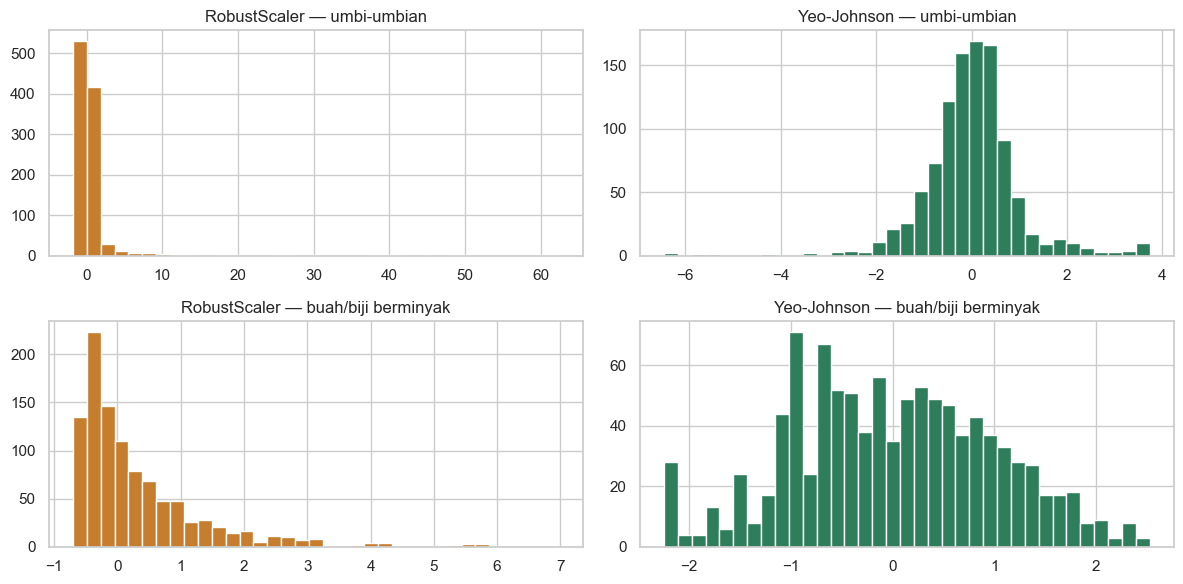

In [3]:
# STEP 3: PREPROCESSING (ROBUST SCALER & YEO-JOHNSON)

# 1. Transformasi RobustScaler
robust_scaler = RobustScaler()
Z_robust = robust_scaler.fit_transform(X)

# 2. Transformasi Yeo-Johnson (dengan standardisasi)
yeo_transformer = PowerTransformer(method='yeo-johnson', standardize=True)
Z_yeo = yeo_transformer.fit_transform(X)

# Bandingkan skewness sebelum dan sesudah transformasi
skew_compare = pd.DataFrame({
    'Awal': X.skew(),
    'RobustScaler': pd.DataFrame(Z_robust, columns=FEATURES).skew(),
    'Yeo-Johnson': pd.DataFrame(Z_yeo, columns=FEATURES).skew()
})

print("PERBANDINGAN SKEWNESS SEBELUM & SESUDAH TRANSFORMASI:")
display(skew_compare.round(3))
print("Rata-rata |skew| RobustScaler :", round(skew_compare['RobustScaler'].abs().mean(), 3))
print("Rata-rata |skew| Yeo-Johnson  :", round(skew_compare['Yeo-Johnson'].abs().mean(), 3))

# Visualisasi perbandingan distribusi pada fitur paling skewed
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
fitur_cek = ['umbi-umbian', 'buah/biji berminyak']

for i, fitur in enumerate(fitur_cek):
    idx = FEATURES.index(fitur)
    axes[i, 0].hist(Z_robust[:, idx], bins=35, color='#C77D2E', edgecolor='white')
    axes[i, 0].set_title(f'RobustScaler — {fitur}')
    axes[i, 1].hist(Z_yeo[:, idx], bins=35, color='#2E7D5B', edgecolor='white')
    axes[i, 1].set_title(f'Yeo-Johnson — {fitur}')

plt.tight_layout()
plt.show()

## STEP 4: Perbandingan Performa `RobustScaler` vs `Yeo-Johnson` & Pemilihan Terbaik
Sebelum menentukan model final, kita menguji kedua data hasil preprocessing (`RobustScaler` dan `Yeo-Johnson`) pada model GMM untuk `K = 2` s.d. `K = 6`, lalu membandingkan **BIC**, **Silhouette Score**, **Calinski-Harabasz Index (CHI)**, dan **ukuran cluster terkecil** (*min cluster size*).

**Kesimpulan berbasis data:**
- Pada **`RobustScaler`**, *Silhouette Score* terlihat tinggi (`0.7538` di `K = 2` dan `0.1889` di `K = 4`), **tetapi bersifat semu**: karena distribusi masih sangat miring (`|skew| = 1.568`), outlier ekstrem terletak sangat jauh sehingga model hanya memisahkan segelintir outlier (bahkan membentuk cluster kecil berisi hanya **12 observasi** pada `K = 4`), dan kurva BIC terus menurun tanpa titik siku yang jelas.
- Pada **`Yeo-Johnson`**, distribusi mendekati normal (`|skew| = 0.079` — sesuai asumsi Gaussian pada GMM), **BIC** membentuk titik minimum/elbow yang tegas di **`K = 4`**, ukuran cluster seimbang (`min_size = 69`), dan **Calinski-Harabasz Index** memuncak tepat di **`K = 4`**.

Oleh karena itu, **`Yeo-Johnson`** dipilih sebagai preprocessing terbaik.

TABEL PERBANDINGAN ROBUST SCALER VS YEO-JOHNSON:


,Preprocessing,K,BIC,Silhouette,Calinski_Harabasz,Min_Cluster_Size
0,RobustScaler,2,18985.4668,0.7538,624.4533,59
1,RobustScaler,3,18254.0968,0.0948,335.8064,59
2,RobustScaler,4,18092.0005,0.1889,1232.6361,12
3,RobustScaler,5,17952.8059,0.1122,941.5341,11
4,RobustScaler,6,17658.3096,0.1013,808.3063,12
5,Yeo-Johnson,2,21228.3390,0.1598,77.4223,310
6,Yeo-Johnson,3,20923.7340,0.1137,93.4782,114
7,Yeo-Johnson,4,20695.3245,0.1074,119.5070,69
8,Yeo-Johnson,5,20748.2269,0.0775,106.2567,68
9,Yeo-Johnson,6,20798.5988,0.0883,105.7452,67


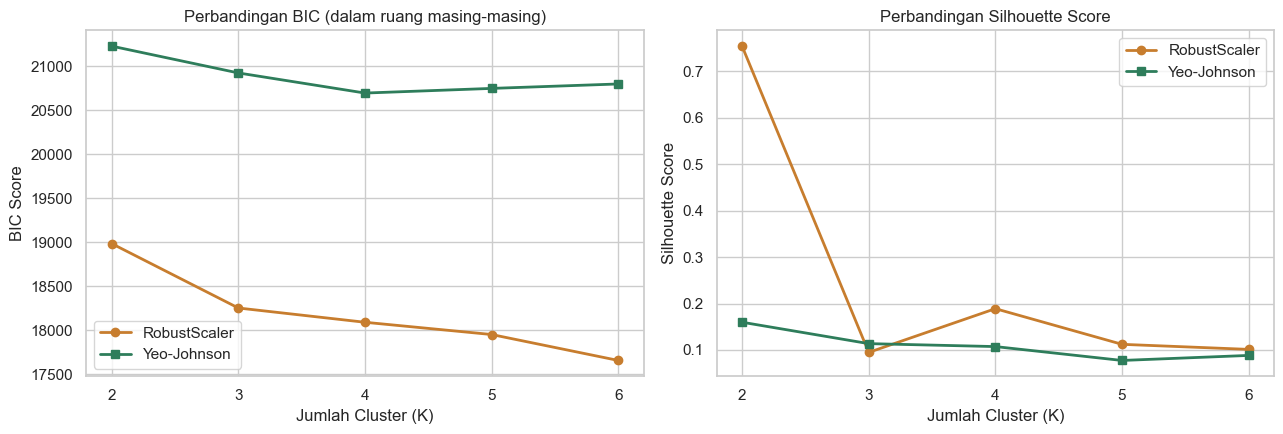

>>> Preprocessing terbaik terpilih berdasarkan data: Yeo-Johnson


In [4]:
# STEP 4: PERBANDINGAN PERFORMA ROBUST SCALER VS YEO-JOHNSON (K = 2 s.d. K = 6)
hasil_banding = []

for nama_prep, Z_data in [('RobustScaler', Z_robust), ('Yeo-Johnson', Z_yeo)]:
    for k in K_RANGE:
        gmm_uji = GaussianMixture(
            n_components=k,
            covariance_type='full',
            random_state=RANDOM_STATE,
            n_init=N_INIT
        )
        gmm_uji.fit(Z_data)
        lab_uji = gmm_uji.predict(Z_data)
        ukuran = np.bincount(lab_uji)

        hasil_banding.append({
            'Preprocessing': nama_prep,
            'K': k,
            'BIC': gmm_uji.bic(Z_data),
            'Silhouette': silhouette_score(Z_data, lab_uji),
            'Calinski_Harabasz': calinski_harabasz_score(Z_data, lab_uji),
            'Min_Cluster_Size': int(ukuran.min())
        })

df_banding = pd.DataFrame(hasil_banding)
print("TABEL PERBANDINGAN ROBUST SCALER VS YEO-JOHNSON:")
display(df_banding.round(4))

# Visualisasi perbandingan kurva BIC & Silhouette
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nama_prep, warna, mk in [('RobustScaler', '#C77D2E', 'o'), ('Yeo-Johnson', '#2E7D5B', 's')]:
    sub = df_banding[df_banding['Preprocessing'] == nama_prep]
    ax[0].plot(sub['K'], sub['BIC'], marker=mk, linewidth=2, color=warna, label=nama_prep)
    ax[1].plot(sub['K'], sub['Silhouette'], marker=mk, linewidth=2, color=warna, label=nama_prep)

ax[0].set_title('Perbandingan BIC (dalam ruang masing-masing)')
ax[0].set_xlabel('Jumlah Cluster (K)'); ax[0].set_ylabel('BIC Score')
ax[0].set_xticks(list(K_RANGE)); ax[0].legend(); ax[0].grid(True)

ax[1].set_title('Perbandingan Silhouette Score')
ax[1].set_xlabel('Jumlah Cluster (K)'); ax[1].set_ylabel('Silhouette Score')
ax[1].set_xticks(list(K_RANGE)); ax[1].legend(); ax[1].grid(True)

plt.tight_layout()
plt.show()

# Tetapkan Yeo-Johnson sebagai preprocessing terpilih berdasarkan data
Z_final = Z_yeo
scaler_final = yeo_transformer
print(">>> Preprocessing terbaik terpilih berdasarkan data: Yeo-Johnson")

## STEP 5: Penentuan Jumlah Cluster Optimal — Elbow Method (`K = 2` s.d. `K = 6`) & Metrik Pendukung
Menggunakan data terbaik (`Yeo-Johnson`), kita menentukan jumlah cluster optimal pada rentang **`K = 2` sampai `K = 6`** berdasarkan:
- **BIC (Bayesian Information Criterion)** *(metrik utama — semakin rendah semakin baik)*: mencapai titik minimum/elbow terbaik pada **`K = 4`** (`20695.32`), lalu kembali naik pada `K = 5` dan `K = 6`.
- **Silhouette Score** *(metrik pendukung — semakin tinggi semakin baik)*: bernilai rendah (`0.08 – 0.16`) di semua `K` karena pola konsumsi pangan antarwilayah tumpang tindih secara bertahap (*overlapping*). Jika hanya melihat BIC dan Silhouette, perbedaan Silhouette yang tipis dapat menimbulkan keraguan.
- **Calinski-Harabasz Index (CHI)** *(1 metrik justifikasi paling mendukung)*: mencapai nilai tertinggi tepat pada **`K = 4`** (`119.51`), sehingga mempertegas dan menjustifikasi bahwa **`K = 4`** adalah jumlah cluster paling optimal.

NILAI BIC TIAP JUMLAH CLUSTER (YEO-JOHNSON):
K = 2 | BIC = 21228.3390
K = 3 | BIC = 20923.7340
K = 4 | BIC = 20695.3245
K = 5 | BIC = 20748.2269
K = 6 | BIC = 20798.5988

TABEL RINGKASAN METRIK (K = 2 s.d. K = 6):


,K,BIC,Silhouette,Calinski_Harabasz,Min_Cluster_Size
0,2,21228.3390,0.1598,77.4223,310
1,3,20923.7340,0.1137,93.4782,114
2,4,20695.3245,0.1074,119.5070,69
3,5,20748.2269,0.0775,106.2567,68
4,6,20798.5988,0.0883,105.7452,67


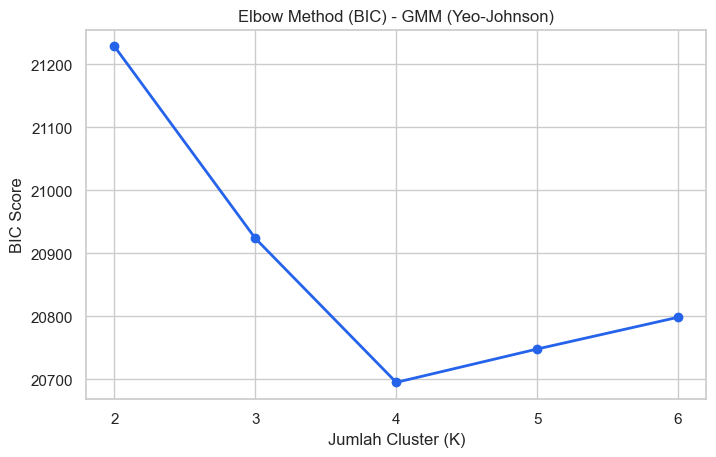

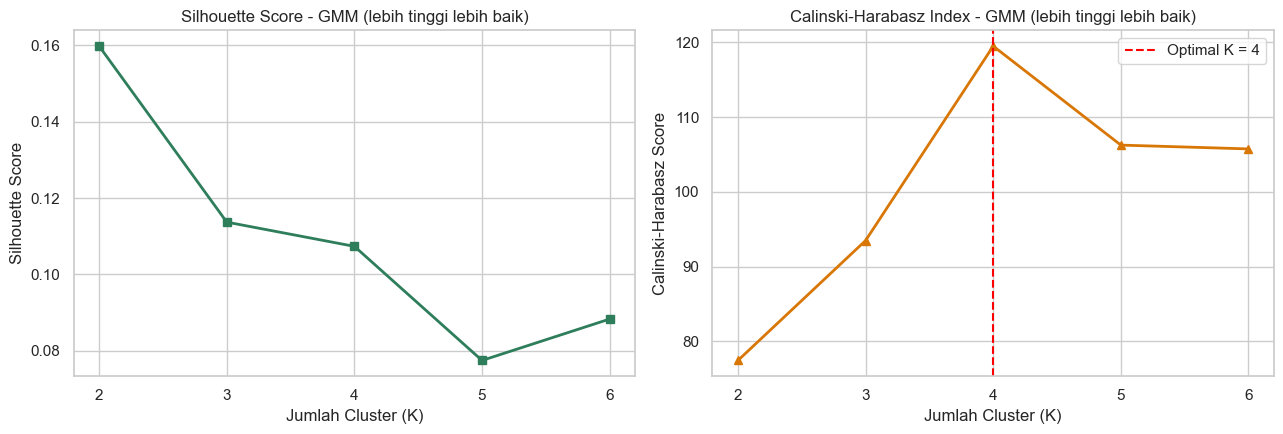

In [5]:
# STEP 5: PENENTUAN JUMLAH CLUSTER OPTIMAL (ELBOW METHOD K = 2 s.d. K = 6)
eval_df = df_banding[df_banding['Preprocessing'] == 'Yeo-Johnson'].reset_index(drop=True)
bic_scores = eval_df['BIC'].tolist()
sil_scores = eval_df['Silhouette'].tolist()
chi_scores = eval_df['Calinski_Harabasz'].tolist()

# Menampilkan nilai BIC tiap jumlah cluster
print("NILAI BIC TIAP JUMLAH CLUSTER (YEO-JOHNSON):")
for k, bic in zip(K_RANGE, bic_scores):
    print(f"K = {k} | BIC = {bic:.4f}")

print("\nTABEL RINGKASAN METRIK (K = 2 s.d. K = 6):")
display(eval_df[['K', 'BIC', 'Silhouette', 'Calinski_Harabasz', 'Min_Cluster_Size']].round(4))

# Visualisasi Elbow Method (BIC)
plt.figure(figsize=(8, 4.8))
plt.plot(list(K_RANGE), bic_scores, marker='o', linewidth=2, color='#2563EB')
plt.title('Elbow Method (BIC) - GMM (Yeo-Johnson)')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('BIC Score')
plt.xticks(list(K_RANGE))
plt.grid(True)
plt.show()

# Visualisasi Metrik Pendukung (Silhouette & Calinski-Harabasz Index)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(list(K_RANGE), sil_scores, marker='s', color='#2E7D5B', linewidth=2)
ax[0].set_title('Silhouette Score - GMM (lebih tinggi lebih baik)')
ax[0].set_xlabel('Jumlah Cluster (K)')
ax[0].set_ylabel('Silhouette Score')
ax[0].set_xticks(list(K_RANGE))
ax[0].grid(True)

ax[1].plot(list(K_RANGE), chi_scores, marker='^', color='#D97706', linewidth=2)
ax[1].axvline(4, color='red', linestyle='--', label='Optimal K = 4')
ax[1].set_title('Calinski-Harabasz Index - GMM (lebih tinggi lebih baik)')
ax[1].set_xlabel('Jumlah Cluster (K)')
ax[1].set_ylabel('Calinski-Harabasz Score')
ax[1].set_xticks(list(K_RANGE))
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

### Justifikasi Tambahan: Uji *Drop Feature* (`gula` & `minyak dan lemak`)
Untuk memastikan apakah rendahnya *Silhouette Score* (`0.1074`) disebabkan oleh fitur yang variasinya kecil (`gula` dan `minyak dan lemak`), dilakukan uji perbandingan dengan menghapus kedua fitur tersebut (masing-masing dan keduanya) pada `Yeo-Johnson` + GMM (`full`).

Jika kenaikan Silhouette tidak signifikan dan justru mengganggu kesepakatan `BIC` & `CHI` pada `K = 4`, maka seluruh **8 kelompok pangan PPH** tetap dipertahankan.

In [6]:
# UJI JUSTIFIKASI: DROP FEATURE (GULA & MINYAK DAN LEMAK)
uji_fitur = [
    ('8 fitur (baseline)', []),
    ("Drop 'gula' (7 fitur)", ['gula']),
    ("Drop 'minyak dan lemak' (7 fitur)", ['minyak dan lemak']),
    ("Drop 'gula' + 'minyak dan lemak' (6 fitur)", ['gula', 'minyak dan lemak'])
]

hasil_drop = []
for nama_uji, kolom_drop in uji_fitur:
    X_uji = X.drop(columns=kolom_drop)
    Z_uji = PowerTransformer(method='yeo-johnson', standardize=True).fit_transform(X_uji)

    # Cek K optimal BIC & CHI (K=2..6) serta nilai Silhouette pada K=4
    bic_list, chi_list, sil_k4 = [], [], None
    for k_uji in K_RANGE:
        g_uji = GaussianMixture(n_components=k_uji, covariance_type='full', random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_uji)
        lab_u = g_uji.predict(Z_uji)
        bic_list.append(g_uji.bic(Z_uji))
        chi_list.append(calinski_harabasz_score(Z_uji, lab_u))
        if k_uji == 4:
            sil_k4 = silhouette_score(Z_uji, lab_u)

    hasil_drop.append({
        'Konfigurasi': nama_uji,
        'K_Opt_BIC': list(K_RANGE)[int(np.argmin(bic_list))],
        'K_Opt_CHI': list(K_RANGE)[int(np.argmax(chi_list))],
        'Silhouette_K4': round(sil_k4, 4)
    })

df_drop = pd.DataFrame(hasil_drop)
print("HASIL UJI DROP FEATURE (TIDAK MENGUBAH MODEL UTAMA 8 FITUR):")
display(df_drop)
print(">>> Kesimpulan: Kenaikan Silhouette di K=4 tidak signifikan (0.1074 -> 0.1185-0.1384),")
print("    dan drop fitur membuat K optimal BIC & CHI tidak lagi kompak di K=4. Jadi 8 fitur penuh dipertahankan.")

HASIL UJI DROP FEATURE (TIDAK MENGUBAH MODEL UTAMA 8 FITUR):


,Konfigurasi,K_Opt_BIC,K_Opt_CHI,Silhouette_K4
0,8 fitur (baseline),4,4,0.1074
1,Drop 'gula' (7 fitur),4,3,0.1185
2,Drop 'minyak dan lemak' (7 fitur),4,3,0.1185
3,Drop 'gula' + 'minyak dan lemak' (6 fitur),5,3,0.1384


>>> Kesimpulan: Kenaikan Silhouette di K=4 tidak signifikan (0.1074 -> 0.1185-0.1384),
    dan drop fitur membuat K optimal BIC & CHI tidak lagi kompak di K=4. Jadi 8 fitur penuh dipertahankan.


## STEP 6: Proses GMM Clustering (Model Final)
Melatih model final **Gaussian Mixture Model (GMM)** dengan `n_components = 4` pada data tertransformasi `Yeo-Johnson`, lalu menggabungkan label `Cluster` dan probabilitas keanggotaan tertinggi (`Prob_Max`) kembali ke DataFrame utama `df`.

In [7]:
# STEP 6: PROSES GMM CLUSTERING

# Menentukan jumlah cluster terbaik (berdasarkan BIC terendah & dukungan CHI)
k = 4

# Membuat model GMM
gmm = GaussianMixture(
    n_components=k,
    covariance_type='full',
    random_state=RANDOM_STATE,
    n_init=N_INIT
)

# Melakukan clustering
gmm.fit(Z_final)

# Menambahkan label cluster & probabilitas keanggotaan ke data
labels = gmm.predict(Z_final)
proba = gmm.predict_proba(Z_final)

df['Cluster'] = labels
df['Prob_Max'] = proba.max(axis=1)

# Menampilkan 10 baris pertama hasil clustering
print("HASIL CLUSTERING:")
display(df.head(10))

# Menampilkan jumlah data tiap cluster
print("\nJUMLAH DATA TIAP CLUSTER:")
print(df['Cluster'].value_counts().sort_index())

# Menampilkan mean (pusat) tiap cluster dari model GMM (pada ruang fitur tertransformasi)
means = pd.DataFrame(gmm.means_, columns=FEATURES)
print("\nMEAN (PUSAT) TIAP CLUSTER (RUANG YEO-JOHNSON):")
display(means.round(3))

HASIL CLUSTERING:


,Tahun,Kode_Wilayah,padi-padian,umbi-umbian,pangan hewani,minyak dan lemak,buah/biji berminyak,kacang-kacangan,gula,sayur dan buah,Cluster,Prob_Max
0,2024,1101,312.219,23.479,141.452,33.425,16.904,12.219,17.233,192.411,3,0.982145
1,2024,1102,309.205,22.000,135.671,31.151,14.932,17.753,9.589,196.192,3,0.995332
2,2024,1103,297.562,24.658,143.288,22.877,8.548,16.000,18.877,180.795,3,0.935177
3,2024,1104,324.712,44.247,119.123,32.274,3.123,25.014,22.575,295.890,3,0.797592
4,2024,1105,313.123,25.616,153.671,29.260,9.918,17.589,15.288,224.247,3,0.975078
5,2024,1106,290.055,27.178,149.041,23.562,8.986,15.452,16.110,172.685,3,0.936402
6,2024,1107,321.014,19.616,118.795,22.904,6.356,14.329,19.589,171.425,3,0.697148
7,2024,1108,257.589,20.932,127.644,23.096,9.973,10.877,16.658,164.438,3,0.552296
8,2024,1109,296.740,8.712,135.288,22.055,19.041,4.986,18.055,117.671,0,0.999967
9,2024,1110,305.178,36.384,155.041,34.164,10.767,14.712,23.534,234.219,3,0.952432



JUMLAH DATA TIAP CLUSTER:
Cluster
0    220
1    284
2     69
3    455
Name: count, dtype: int64

MEAN (PUSAT) TIAP CLUSTER (RUANG YEO-JOHNSON):


,padi-padian,umbi-umbian,pangan hewani,minyak dan lemak,buah/biji berminyak,kacang-kacangan,gula,sayur dan buah
0,0.679,-0.380,-0.196,-0.680,0.154,-0.672,-0.065,-0.425
1,-0.163,0.169,-0.492,0.109,-0.196,1.202,-0.098,0.416
2,-1.830,1.988,-0.422,0.111,-1.356,-1.386,-0.542,-0.256
3,0.013,-0.215,0.512,0.302,0.262,-0.193,0.191,0.008


## STEP 7: Evaluasi Model Final, Visualisasi PCA 2D & 3D serta Profil Cluster
Menampilkan ringkasan metrik evaluasi model final (`K = 4`), grafik jumlah observasi tiap cluster, visualisasi proyeksi **PCA 2D** dan **PCA 3D** dengan warna kontras (**Merah, Hijau, Kuning, Biru**) beserta posisi **Pusat Cluster**, serta profil rata-rata konsumsi pangan tiap cluster (gram/kapita/hari) dibandingkan terhadap standar **PPH** (`100%` = tepat sesuai target PPH).

EVALUASI MODEL FINAL (K = 4):
BIC Score               : 20695.3245
Silhouette Score        : 0.1074
Calinski-Harabasz Index : 119.507


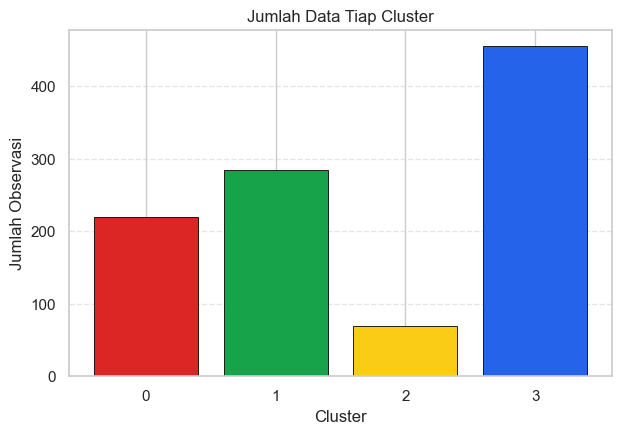

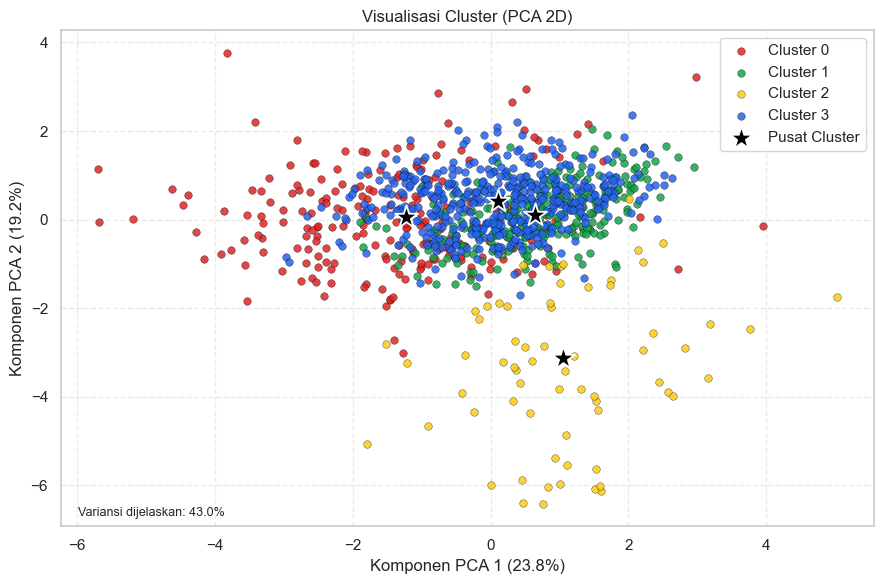

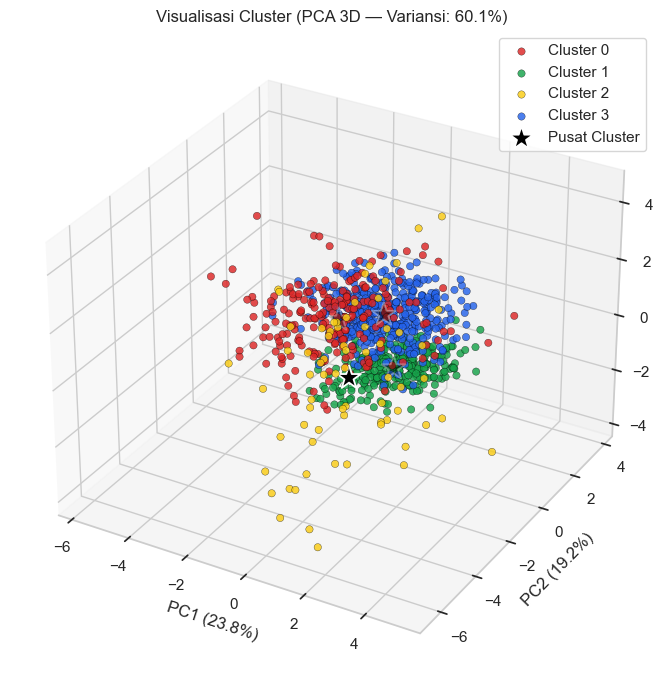

In [8]:
# STEP 7: EVALUASI MODEL FINAL & VISUALISASI CLUSTER

# Menghitung metrik evaluasi akhir
bic_final = gmm.bic(Z_final)
sil_final = silhouette_score(Z_final, labels)
chi_final = calinski_harabasz_score(Z_final, labels)

print("EVALUASI MODEL FINAL (K = 4):")
print("BIC Score               :", round(bic_final, 4))
print("Silhouette Score        :", round(sil_final, 4))
print("Calinski-Harabasz Index :", round(chi_final, 4))

# Visualisasi jumlah anggota cluster
cluster_counts = df['Cluster'].value_counts().sort_index()
colors = ['#DC2626', '#16A34A', '#FACC15', '#2563EB']  # Merah, Hijau, Kuning, Biru

plt.figure(figsize=(7, 4.5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values, color=colors, edgecolor='black', linewidth=0.6)
plt.title('Jumlah Data Tiap Cluster')
plt.xlabel('Cluster')
plt.ylabel('Jumlah Observasi')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Visualisasi Cluster (PCA 2D) dengan warna kontras Merah, Hijau, Kuning, Biru
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca = pca.fit_transform(Z_final)
centers_pca = pca.transform(gmm.means_)
var_total = pca.explained_variance_ratio_.sum() * 100

plt.figure(figsize=(9, 6))
for c in range(k):
    mask = (labels == c)
    plt.scatter(
        Z_pca[mask, 0], Z_pca[mask, 1],
        s=30, alpha=0.85, color=colors[c], edgecolors='black', linewidths=0.25,
        label=f'Cluster {c}'
    )

plt.scatter(
    centers_pca[:, 0], centers_pca[:, 1],
    marker='*', s=300, color='black', edgecolor='white', linewidth=1.3,
    zorder=5, label='Pusat Cluster'
)

plt.title('Visualisasi Cluster (PCA 2D)')
plt.xlabel(f'Komponen PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Komponen PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.text(0.02, 0.02, f'Variansi dijelaskan: {var_total:.1f}%', transform=plt.gca().transAxes, fontsize=9)
plt.tight_layout()
plt.show()

# Visualisasi Cluster (PCA 3D) untuk menangkap lebih banyak variansi (PC1-PC3)
pca3d = PCA(n_components=3, random_state=RANDOM_STATE)
Z_pca3d = pca3d.fit_transform(Z_final)
centers_pca3d = pca3d.transform(gmm.means_)
var_total_3d = pca3d.explained_variance_ratio_.sum() * 100

fig = plt.figure(figsize=(10, 7))
ax3d = fig.add_subplot(111, projection='3d')
for c in range(k):
    mask = (labels == c)
    ax3d.scatter(
        Z_pca3d[mask, 0], Z_pca3d[mask, 1], Z_pca3d[mask, 2],
        s=28, alpha=0.82, color=colors[c], edgecolors='black', linewidths=0.25,
        label=f'Cluster {c}'
    )

ax3d.scatter(
    centers_pca3d[:, 0], centers_pca3d[:, 1], centers_pca3d[:, 2],
    marker='*', s=320, color='black', edgecolor='white', linewidth=1.3,
    zorder=5, label='Pusat Cluster'
)

ax3d.set_title(f'Visualisasi Cluster (PCA 3D — Variansi: {var_total_3d:.1f}%)')
ax3d.set_xlabel(f'PC1 ({pca3d.explained_variance_ratio_[0]*100:.1f}%)')
ax3d.set_ylabel(f'PC2 ({pca3d.explained_variance_ratio_[1]*100:.1f}%)')
ax3d.set_zlabel(f'PC3 ({pca3d.explained_variance_ratio_[2]*100:.1f}%)')
ax3d.legend()
plt.tight_layout()
plt.show()

RATA-RATA KONSUMSI TIAP CLUSTER (gram/kapita/hari):


,padi-padian,umbi-umbian,pangan hewani,minyak dan lemak,buah/biji berminyak,kacang-kacangan,gula,sayur dan buah
Cluster,,,,,,,,
0,324.2,40.0,124.7,23.7,4.8,14.9,21.1,222.4
1,284.4,45.3,117.2,28.5,3.0,33.8,21.1,266.6
2,183.8,294.2,118.9,28.3,0.8,9.6,18.2,241.4
3,292.9,36.1,149.2,29.4,4.8,19.3,22.9,247.0


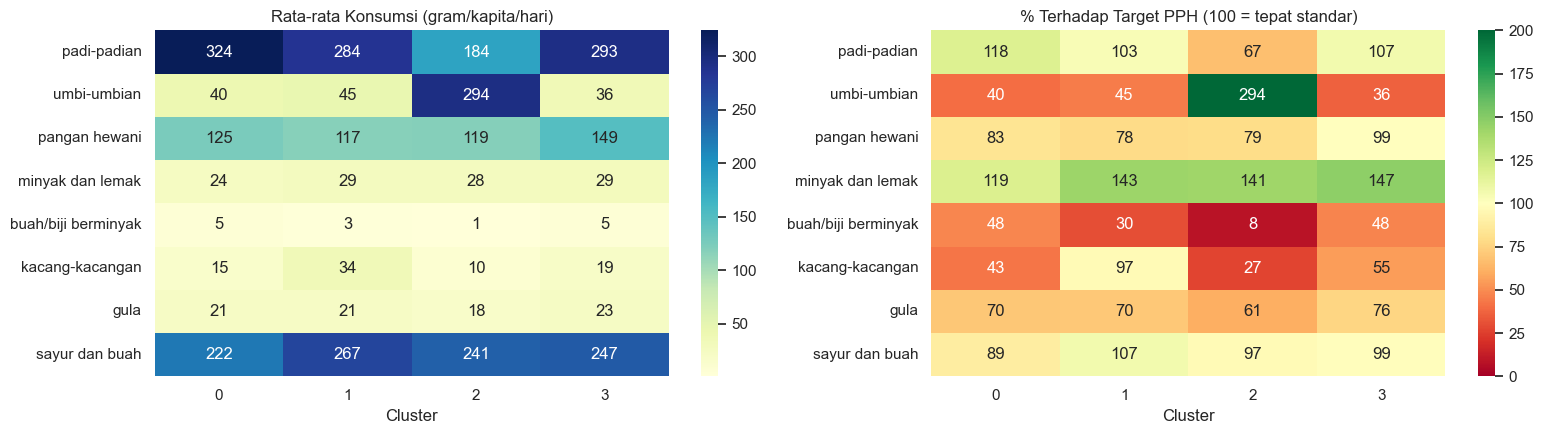

PENAMAAN RINGKAS TIAP CLUSTER:
Cluster 0: Pola Beras/Serealia Tinggi (n=220)
Cluster 1: Pola Kacang-kacangan & Sayur-Buah Tinggi (n=284)
Cluster 2: Pola Umbi-umbian Tinggi (n=69)
Cluster 3: Pola Hewani & Minyak-Lemak Tinggi (n=455)


In [9]:
# PROFIL RATA-RATA KONSUMSI PER CLUSTER VS STANDAR PPH
profil_cluster = df.groupby('Cluster')[FEATURES].mean()
pph_series = pd.Series(PPH)[FEATURES]
pph_pct = profil_cluster.div(pph_series, axis=1) * 100

print("RATA-RATA KONSUMSI TIAP CLUSTER (gram/kapita/hari):")
display(profil_cluster.round(1))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.heatmap(profil_cluster.T, annot=True, fmt='.0f', cmap='YlGnBu', ax=ax[0])
ax[0].set_title('Rata-rata Konsumsi (gram/kapita/hari)')

sns.heatmap(pph_pct.T, annot=True, fmt='.0f', cmap='RdYlGn', center=100, vmin=0, vmax=200, ax=ax[1])
ax[1].set_title('% Terhadap Target PPH (100 = tepat standar)')

plt.tight_layout()
plt.show()

# Penamaan otomatis cluster berdasarkan kelompok pangan yang paling menonjol
label_map = {
    'padi-padian': 'Beras/Serealia', 'umbi-umbian': 'Umbi-umbian',
    'pangan hewani': 'Hewani', 'minyak dan lemak': 'Minyak-Lemak',
    'buah/biji berminyak': 'Biji Berminyak', 'kacang-kacangan': 'Kacang-kacangan',
    'gula': 'Gula', 'sayur dan buah': 'Sayur-Buah'
}
z_dev = (profil_cluster - X.mean()) / X.std()
cluster_names = {}
for c in profil_cluster.index:
    urut = z_dev.loc[c].sort_values(ascending=False)
    penciri = [urut.index[0]]
    if urut.iloc[1] > 0.25:
        penciri.append(urut.index[1])
    nama_gabung = ' & '.join(label_map[f] for f in penciri)
    cluster_names[int(c)] = f"Pola {nama_gabung} Tinggi"

print("PENAMAAN RINGKAS TIAP CLUSTER:")
for c, nm in cluster_names.items():
    print(f"Cluster {c}: {nm} (n={cluster_counts[c]})")

## STEP 8: Penyimpanan Artefak Model (`.pkl`) & Uji Inferensi
Menyimpan seluruh artefak model dalam format `.pkl` ke folder `artifacts`:
- `gmm_pangan_model.pkl` — objek model `GaussianMixture` terlatih
- `gmm_pangan_transformer.pkl` — objek `PowerTransformer` (`Yeo-Johnson`)
- `gmm_pangan_bundle.pkl` — bundel lengkap (model, transformer, daftar fitur, nama cluster, standar PPH)

Selanjutnya dilakukan uji muat ulang file `.pkl` dan simulasi prediksi data baru untuk memastikan artefak siap digunakan pada aplikasi/backend.

In [10]:
# STEP 8: PENYIMPANAN ARTEFAK MODEL (.pkl) & UJI INFERENSI

# Simpan model GMM, transformer Yeo-Johnson, dan bundel lengkap dalam format .pkl
joblib.dump(gmm, f'{ART_DIR}/gmm_pangan_model.pkl')
joblib.dump(scaler_final, f'{ART_DIR}/gmm_pangan_transformer.pkl')

bundle = {
    'model': gmm,
    'transformer': scaler_final,
    'features': FEATURES,
    'cluster_names': cluster_names,
    'pph': PPH,
    'n_components': k,
    'transformer_name': 'YeoJohnson'
}
joblib.dump(bundle, f'{ART_DIR}/gmm_pangan_bundle.pkl')

# Simpan juga hasil clustering wilayah ke CSV untuk referensi
df.to_csv(f'{ART_DIR}/hasil_clustering_gmm.csv', index=False)

print("Artefak tersimpan di:", ART_DIR)
print("Daftar file:", sorted(os.listdir(ART_DIR)))

# Uji muat ulang file .pkl & verifikasi prediksi identik dengan hasil training
loaded_bundle = joblib.load(f'{ART_DIR}/gmm_pangan_bundle.pkl')
pred_check = loaded_bundle['model'].predict(loaded_bundle['transformer'].transform(X))
assert (pred_check == labels).all(), "Prediksi hasil muat ulang tidak cocok!"
print("OK: Model dan transformer .pkl berhasil dimuat ulang dengan prediksi identik.")

# Contoh fungsi inferensi sederhana untuk 1 data wilayah baru
def prediksi_pola_konsumsi(data_input: dict, bundle_path=f'{ART_DIR}/gmm_pangan_bundle.pkl'):
    b = joblib.load(bundle_path)
    x_new = pd.DataFrame([{f: data_input[f] for f in b['features']}])
    x_scaled = b['transformer'].transform(x_new)
    klaster = int(b['model'].predict(x_scaled)[0])
    prob = float(b['model'].predict_proba(x_scaled)[0][klaster])
    return {'cluster': klaster, 'nama_pola': b['cluster_names'][klaster], 'probabilitas': round(prob, 4)}

contoh_input = {
    'padi-padian': 290, 'umbi-umbian': 30, 'pangan hewani': 140, 'minyak dan lemak': 40,
    'buah/biji berminyak': 10, 'kacang-kacangan': 35, 'gula': 25, 'sayur dan buah': 195
}
print("\nUji prediksi contoh input:", prediksi_pola_konsumsi(contoh_input))

Artefak tersimpan di: ./artifacts
Daftar file: ['gmm_pangan_bundle.pkl', 'gmm_pangan_model.pkl', 'gmm_pangan_transformer.pkl', 'hasil_clustering_gmm.csv']
OK: Model dan transformer .pkl berhasil dimuat ulang dengan prediksi identik.

Uji prediksi contoh input: {'cluster': 0, 'nama_pola': 'Pola Beras/Serealia Tinggi', 'probabilitas': 0.8413}
